Original dataset shape: (1338, 7)

First five rows:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing values:
age  

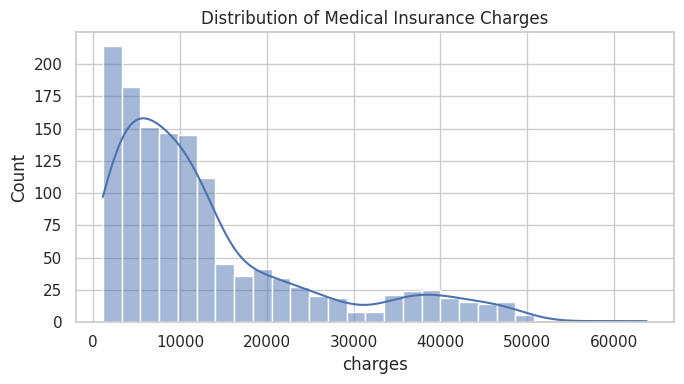

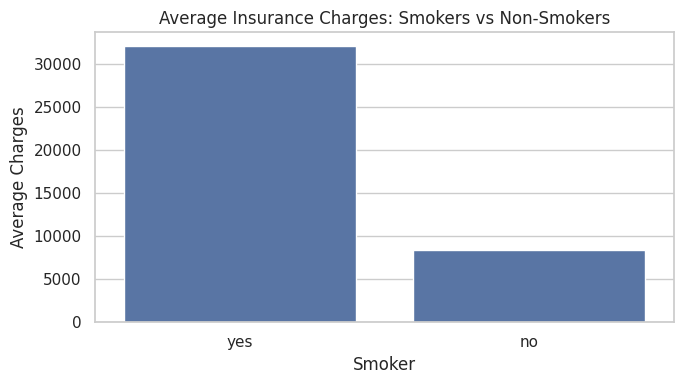

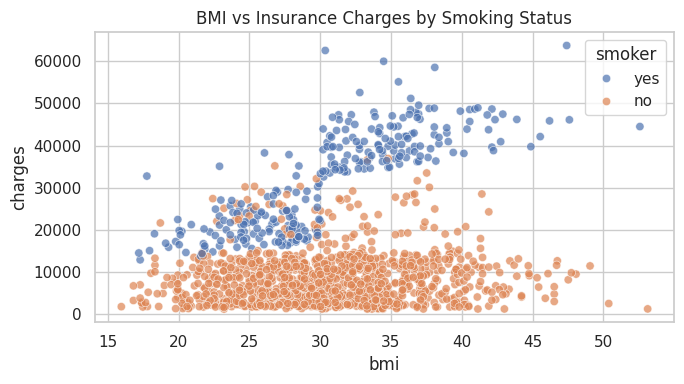

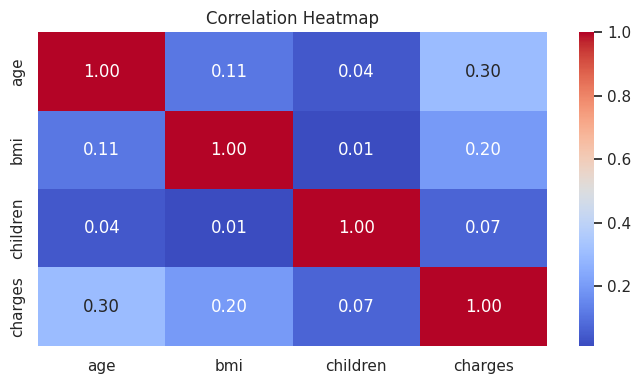

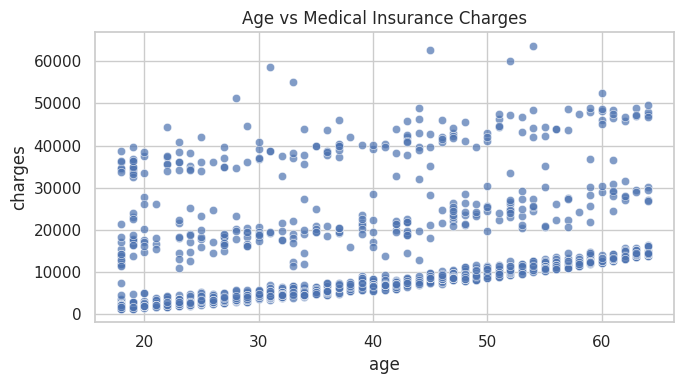


--- MODEL EVALUATION ---
R2 Score: 0.8868
MAE: 2813.07
RMSE: 4560.55


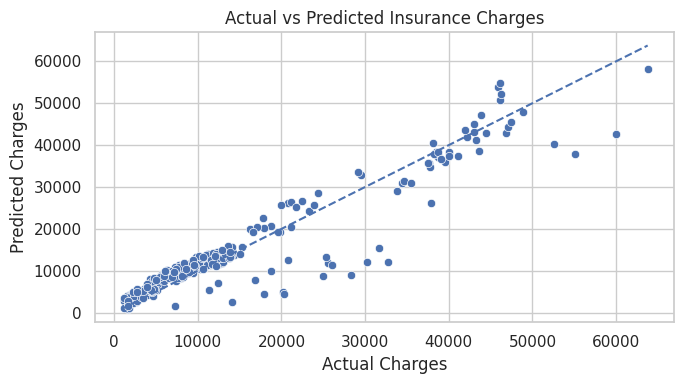


--- TOP 10 FEATURES BY ABSOLUTE COEFFICIENT ---
                Feature   Coefficient  Absolute_Impact
             smoker_yes -21728.495926     21728.495926
     bmi_category_obese   4253.224181      4253.224181
             smoker_bmi   1477.400199      1477.400199
    bmi_category_normal   1084.641765      1084.641765
       region_southwest   -970.042436       970.042436
bmi_category_overweight    860.747426       860.747426
       region_southeast   -742.657188       742.657188
               sex_male   -630.649153       630.649153
               children    572.280181       572.280181
       region_northwest   -476.627136       476.627136

--- AVERAGE CHARGES BY SMOKING STATUS ---
            mean    median  count
smoker                           
no       8440.66   7345.73   1063
yes     32050.23  34456.35    274

--- PROJECT SUMMARY ---
Target variable: charges
Model: Linear Regression
Training samples: 1069
Testing samples: 268
R2: 0.8868
MAE: 2813.07
RMSE: 4560.55

Project e

In [1]:

# MEDICAL INSURANCE COST PREDICTION
# AIML Mini Project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

# 1. Load dataset
df = pd.read_csv("/content/insurance.csv")

print("Original dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nDataset information:")
df.info()

# 2. Data cleaning
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Standardize categorical text
for col in ["sex", "smoker", "region"]:
    df[col] = df[col].astype(str).str.strip().str.lower()

# Remove invalid records and any missing values
df = df.dropna(subset=[
    "age", "sex", "bmi", "children",
    "smoker", "region", "charges"
])

df = df[
    (df["age"] > 0) &
    (df["bmi"] > 0) &
    (df["charges"] > 0) &
    (df["children"] >= 0)
].copy()

print("\nCleaned dataset shape:", df.shape)

# 3. Exploratory Data Analysis (EDA)

# Visualization 1: Insurance charge distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="charges", kde=True)
plt.title("Distribution of Medical Insurance Charges")
plt.tight_layout()
plt.show()

# Visualization 2: Charges by smoking status
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="smoker", y="charges", errorbar=None)
plt.title("Average Insurance Charges: Smokers vs Non-Smokers")
plt.xlabel("Smoker")
plt.ylabel("Average Charges")
plt.tight_layout()
plt.show()

# Visualization 3: BMI vs charges, by smoking status
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=df, x="bmi", y="charges",
    hue="smoker", alpha=0.7
)
plt.title("BMI vs Insurance Charges by Smoking Status")
plt.tight_layout()
plt.show()

# Visualization 4: Numeric correlation heatmap
plt.figure(figsize=(7, 4))
sns.heatmap(
    df[["age", "bmi", "children", "charges"]].corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Optional fifth visualization: Charges by age
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="age", y="charges", alpha=0.7)
plt.title("Age vs Medical Insurance Charges")
plt.tight_layout()
plt.show()

# 4. Feature engineering
df["bmi_category"] = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 25, 30, float("inf")],
    labels=["underweight", "normal", "overweight", "obese"],
    right=False
)

# Interaction feature: smoker status multiplied by BMI
df["smoker_bmi"] = (
    (df["smoker"] == "yes").astype(int) * df["bmi"]
)

# Encode categorical columns
df_encoded = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region", "bmi_category"],
    drop_first=True,
    dtype=int
)

# 5. Prepare features and target
X = df_encoded.drop(columns=["charges"])
y = df_encoded["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# 7. Evaluate the model
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n--- MODEL EVALUATION ---")
print(f"R2 Score: {r2:.4f}")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

# 8. Actual vs predicted visualization
plt.figure(figsize=(7, 4))
sns.scatterplot(x=y_test, y=y_pred)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")
plt.tight_layout()
plt.show()

# 9. Feature impact analysis
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients["Absolute_Impact"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute_Impact", ascending=False
)

print("\n--- TOP 10 FEATURES BY ABSOLUTE COEFFICIENT ---")
print(coefficients.head(10).to_string(index=False))

# 10. Compare smoking groups
print("\n--- AVERAGE CHARGES BY SMOKING STATUS ---")
print(df.groupby("smoker")["charges"].agg(
    ["mean", "median", "count"]
).round(2))

# 11. Generate project summary
print("\n--- PROJECT SUMMARY ---")
print("Target variable: charges")
print("Model: Linear Regression")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("R2:", round(r2, 4))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

print("\nProject execution completed.")
